# W1｜了解專案與資料檢查（2026 年 7 月歷史租借紀錄）

本週目標：下載一個月的歷史租借紀錄，檢查資料的大小、型態、缺漏與重複。**只發現並記錄問題，不修改資料、不建模。**

每個檢查的順序：目的 → 程式 → 看到什麼 → 我的判斷（用自己的話寫）。

| 段 | 內容 | 對應範本 |
|---|---|---|
| 1 | 環境準備、讀取歷史資料索引檔 | 第 0、2 節 |
| 2 | 下載 zip、解壓縮、用 DuckDB 看整份資料 | 第 2、3、4 節 |
| 3 | 型態檢查：`rent` 是時刻還是時間長度 | 第 4 節 |
| 4 | 少了哪一天 | 第 5 節 |
| 5 | 缺漏的時段從幾點到幾點 | 第 5 節 |
| 6 | 每個欄位的空值、完全相同的資料列 | 第 5、6 節 |
| 7 | 看實際的重複例子和空值列 | 第 6 節 |
| 8 | 驗證調度的推測、騎乘時間的範圍 | 第 7 節 |

## 第 1 段：環境準備＋讀取歷史資料索引檔

**目的**：在 Colab 準備好工具，再從官方的索引檔找出 2026 年 7 月的下載網址。

歷史資料不是一般的 API。官方先提供一份 CSV 目錄，每一列是一個月份和它的 zip 下載網址。流程是：先讀目錄 → 找到網址 → 再下載。

### 步驟 1：環境準備（每次重開 Colab 都要先執行這格）

In [ ]:
# ---- 安裝套件：Colab 預設沒有 DuckDB ----
!pip install -q duckdb  # -q：安靜模式，不顯示安裝過程

# ---- 載入套件 ----
import sys, json, re, unicodedata, warnings
from pathlib import Path                 # Path：用物件的方式處理檔案路徑，可以用 / 串接
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
from google.colab import drive

# ---- 掛載 Google Drive：zip 存在雲端，Colab 斷線也不會不見 ----
drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive/youbike/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)  # parents：連上層資料夾一起建立；exist_ok：已經存在也不報錯

# ---- 顯示設定 ----
warnings.filterwarnings("ignore", category=FutureWarning)  # 隱藏「未來版本會改變」的提醒
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.max_rows", 120)

# ---- 圖表的中文字型：先找系統內建的，沒有（例如 Colab）就下載 Noto Sans TC ----
FONT_URL = "https://raw.githubusercontent.com/google/fonts/main/ofl/notosanstc/NotoSansTC%5Bwght%5D.ttf"


def setup_chinese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}  # 系統已安裝的字型名稱
    for name in ["Noto Sans CJK TC", "Noto Sans TC", "Microsoft JhengHei", "PingFang TC", "Heiti TC"]:
        if name in installed:
            return name
    try:
        import urllib.request
        path = Path("NotoSansTC-Regular.ttf")
        if not path.exists():
            urllib.request.urlretrieve(FONT_URL, path)
        font_manager.fontManager.addfont(str(path))  # 把字型加進 matplotlib
        return font_manager.FontProperties(fname=str(path)).get_name()
    except Exception:
        return None  # 下載失敗就回傳 None，改用預設字型


FONT = setup_chinese_font()
plt.rcParams.update({
    "font.family": FONT or "DejaVu Sans",  # FONT 是 None 時改用 DejaVu Sans
    "axes.unicode_minus": False,           # 讓負號正常顯示
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
})
if FONT is None:
    print("⚠ 找不到中文字型，圖上的中文可能變成方塊，不影響分析")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}")

Mounted at /content/drive
Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6


**看到什麼**

Drive 掛載成功。環境是 Python 3.13.18、pandas 2.2.3、numpy 2.4.6，沒有出現找不到字型的警告。

### 步驟 2：讀取索引檔，找出 2026 年 7 月的下載網址

In [ ]:
INDEX_URL = "https://tcgbusfs.blob.core.windows.net/dotapp/youbike_second_ticket_opendata/YouBikeHis.csv"
index_df = pd.read_csv(INDEX_URL)  # read_csv 可以直接讀網址

print(index_df.shape)              # shape：(列數, 欄數)
display(index_df.head())           # head()：看前 5 列

# 用布林條件挑出 2026年7月 那一列，再取出下載網址
row = index_df[index_df["fileinfo"] == "2026年7月"]
ZIP_URL = row["fileURL"].iloc[0]   # iloc[0]：取第一個值
print(ZIP_URL)

(76, 4)


,UpdateTime,SrcUpdateTime,fileinfo,fileURL
0,2026-09-07T10:10:20+08:00,2026-09-07T10:10:20+08:00,2026年7月,https://tcgbusfs.blob.core.windows.net/dotapp/...
1,2026-09-07T10:10:20+08:00,2026-09-07T10:10:20+08:00,2026年6月,https://tcgbusfs.blob.core.windows.net/dotapp/...
2,2026-09-07T10:10:20+08:00,2026-09-07T10:10:20+08:00,2026年5月,https://tcgbusfs.blob.core.windows.net/dotapp/...
3,2026-09-07T10:10:20+08:00,2026-09-07T10:10:20+08:00,2026年4月,https://tcgbusfs.blob.core.windows.net/dotapp/...
4,2026-04-07T15:10:20+08:00,2026-04-07T15:10:20+08:00,2026年3月,https://tcgbusfs.blob.core.windows.net/dotapp/...


https://tcgbusfs.blob.core.windows.net/dotapp/youbike_second_ticket_opendata/2026/2026-07/202607_YouBike2.0票證刷卡資料.zip


**看到什麼**

- 索引共 **76 列、4 欄**，一列代表一個月份（2020 年 4 月到 2026 年 7 月）。
- 最新一列是 2026 年 7 月，`UpdateTime` 是 **2026-09-07**；2026 年 3 月則是 2026-04-07 上架。官方大約晚 1~2 個月才公開資料。
- 成功取得 2026 年 7 月的 zip 下載網址。

**我的判斷：**（提示：索引的月份數和資料定義文件的 76 個月一致嗎？官方晚 1~2 個月才上架，對「用歷史資料預測現在」有什麼影響？）

## 第 2 段：下載 zip、解壓縮、用 DuckDB 看整份資料

**目的**：把資料下載下來，在不把整份檔案讀進記憶體的情況下，先知道它有幾列、有哪些欄位。

存放位置的設計：
- **zip（約 130 MB）存在 Drive**：只下載一次，斷線後不用重新下載。
- **CSV（約 890 MB）解壓縮到 Colab 本機 `/content`**：讀取比 Drive 快很多。斷線後檔案會消失，重新解壓縮只要幾十秒。

### 步驟 1：下載 zip 到 Drive

In [ ]:
import requests, zipfile

zip_path = DATA_DIR / "202607.zip"  # Path 可以用 / 把資料夾和檔名接起來

if not zip_path.exists():           # 已經下載過就跳過
    r = requests.get(ZIP_URL, stream=True, timeout=60)  # stream=True：分批下載，不一次放進記憶體
    r.raise_for_status()                                # 下載失敗就直接報錯
    with open(zip_path, "wb") as f:                     # "wb"：用二進位模式寫入
        for chunk in r.iter_content(chunk_size=1024 * 1024):  # 每次寫 1 MB
            f.write(chunk)

print(round(zip_path.stat().st_size / 1024**2, 1), "MB")  # st_size 是位元組數，除以 1024² 換成 MB

126.6 MB


**看到什麼**

Drive 上的 `202607.zip` 約 **126.6 MB**。

### 步驟 2：看 zip 裡面有什麼，再解壓縮到 /content

In [ ]:
EXTRACT_DIR = Path("/content/youbike_202607")

with zipfile.ZipFile(zip_path) as z:     # with：區塊結束時自動關閉檔案
    for info in z.infolist():            # infolist()：zip 裡每個檔案的檔名和大小
        print(info.filename, round(info.file_size / 1024**2, 1), "MB")
    z.extractall(EXTRACT_DIR)            # 全部解壓縮到指定資料夾

# zip 裡的中文檔名可能有編碼問題，所以不寫死檔名，改用 glob 找 .csv
CSV_PATH = next(EXTRACT_DIR.glob("**/*.csv"))  # **：包含子資料夾；next()：取第一個找到的檔案
print(CSV_PATH)

YouBike2.0票證刷卡資料_202607.csv 845.3 MB
/content/youbike_202607/YouBike2.0票證刷卡資料_202607.csv


**看到什麼**

zip 裡只有一個檔案 `YouBike2.0票證刷卡資料_202607.csv`，解壓縮後 **845.3 MB**，中文檔名沒有亂碼。

### 步驟 3：用 DuckDB 算列數、看欄位型態

DuckDB 可以直接對 CSV 檔下 SQL，不用先把整份資料讀進 pandas。

In [ ]:
import duckdb

# 這份 CSV 總共有幾列？
duckdb.sql(f"SELECT COUNT(*) FROM read_csv_auto('{CSV_PATH}')").show()

# 每個欄位被判斷成什麼型態？DESCRIBE：描述查詢結果的欄位名稱和型態
duckdb.sql(f"DESCRIBE SELECT * FROM read_csv_auto('{CSV_PATH}')").show()

# f"..."：f-string，{CSV_PATH} 會被換成實際的檔案路徑
# read_csv_auto：讓 DuckDB 自動判斷分隔符號、標題列和欄位型態

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│      7596992 │
└──────────────┘

┌────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│  column_name   │ column_type │  null   │   key   │ default │  extra  │
│    varchar     │   varchar   │ varchar │ varchar │ varchar │ varchar │
├────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ rent_time      │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ rent_station   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ return_time    │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ return_station │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rent           │ TIME        │ YES     │ NULL    │ NULL    │ NULL    │
│ bike_type      │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ infodate       │ DATE        │ YES     │ NULL    │ NULL    │ NULL    │
└────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘



**看到什麼**

- 共 **7,596,992 列、7 欄**，和資料定義文件的數字一致。
- DuckDB 自動判斷的型態：`rent_time`、`return_time` 是 TIMESTAMP（日期＋時間），`rent_station`、`return_station`、`bike_type` 是 VARCHAR（文字），`rent` 是 **TIME**，`infodate` 是 DATE。

**我的判斷：**（提示：列數、欄數和官方說明一致嗎？哪個欄位的型態跟它的意思對不上？）

## 第 3 段：型態檢查，`rent` 是「時刻」還是「時間長度」？

**目的**：DuckDB 只看前面一部分資料就猜型態，可能猜錯。

- `TIME` 代表「一天中的某個時刻」，例如 08:30:00，範圍只到 23:59:59。
- `rent` 的意思是「騎了多久」，是一段**時間長度**。

### 步驟 1：照 DuckDB 猜的型態算最大值，會發生什麼事

In [ ]:
# 這格執行會報錯，錯誤訊息就是要看的結果（內容整理在下方「看到什麼」）。
# 為了讓整本 notebook 可以從頭跑到尾，先把它註解掉；想重現錯誤時，把下一行最前面的 # 拿掉。
# duckdb.sql(f"SELECT MAX(rent) FROM read_csv_auto('{CSV_PATH}')").show()

**看到什麼**

報錯 `ConversionException`：第 20,921 行的 `rent` 是 **88:17:16**（7/17 07:00 借車、7/21 00:00 還車），無法轉成 TIME。

錯誤訊息裡有一行 `sample_size = 20480`：DuckDB 只看前 20,480 列就決定型態，而前面剛好都是 24 小時內的騎乘。

**我的判斷：**（提示：`rent` 應該是什麼型態？DuckDB 為什麼會猜錯？）

### 步驟 2：改用文字讀，找出騎超過 24 小時的紀錄

In [ ]:
duckdb.sql(f"""
SELECT
    COUNT(*)                                       AS 超過24小時筆數,
    MAX(CAST(split_part(rent, ':', 1) AS INTEGER)) AS 最長小時數
FROM read_csv('{CSV_PATH}', all_varchar=true)
WHERE CAST(split_part(rent, ':', 1) AS INTEGER) >= 24
""").show()

# all_varchar=true：每個欄位都先當文字讀，就不會被猜錯的型態卡住
# split_part(rent, ':', 1)：用冒號切開，取第 1 段，也就是「小時」
# CAST(... AS INTEGER)：把文字轉成整數。文字比大小會出錯（"99" 會大於 "100"），所以要先轉

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────┬────────────┐
│ 超過24小時筆數 │ 最長小時數 │
│     int64      │   int32    │
├────────────────┼────────────┤
│            382 │        386 │
└────────────────┴────────────┘



**看到什麼**

小時數 ≥ 24 的紀錄有 **382 筆**（約占全部的 0.005%），最長 **386 小時**（約 16 天）。

**我的判斷：**（提示：騎超過 24 小時合理嗎？可能是什麼情況（先不要下定論）？W2 打算怎麼處理？）

### 步驟 3：資料涵蓋的日期範圍與天數

In [ ]:
duckdb.sql(f"""
SELECT
    MIN(rent_time)           AS 最早借車,
    MAX(rent_time)           AS 最晚借車,
    COUNT(DISTINCT infodate) AS 天數
FROM read_csv_auto('{CSV_PATH}')
""").show()

# COUNT(DISTINCT 欄位)：重複的值只算一次，也就是「有幾種不同的值」
# 這格沒用到 rent，DuckDB 只讀需要的欄位，所以不會遇到 88:17:16 那種值而報錯

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌─────────────────────┬─────────────────────┬───────┐
│      最早借車       │      最晚借車       │ 天數  │
│      timestamp      │      timestamp      │ int64 │
├─────────────────────┼─────────────────────┼───────┤
│ 2026-07-01 00:00:00 │ 2026-07-31 23:00:00 │    30 │
└─────────────────────┴─────────────────────┴───────┘



**看到什麼**

`rent_time` 從 **2026-07-01 00:00** 到 **2026-07-31 23:00**，但 `infodate` 只有 **30 個不同的日期**；7 月有 31 天。

**我的判斷：**（提示：只看最小值和最大值，能確定中間每一天都有資料嗎？為什麼？）

## 第 4 段：少了哪一天？

**目的**：每天算一次筆數，再跟完整的 7 月日曆比對，找出沒有資料的日期。

### 步驟 1：每天的借車筆數

In [ ]:
duckdb.sql(f"""
SELECT
    infodate,
    COUNT(*) AS trip_count
FROM read_csv_auto('{CSV_PATH}')
GROUP BY infodate
ORDER BY infodate
""").show()

# GROUP BY：把同一天的列分成一組，COUNT(*) 就變成「每天幾筆」
# ORDER BY：依日期由早到晚排序

┌────────────┬────────────┐
│  infodate  │ trip_count │
│    date    │   int64    │
├────────────┼────────────┤
│ 2026-07-01 │     286998 │
│ 2026-07-02 │     265111 │
│ 2026-07-03 │     275791 │
│ 2026-07-04 │     239956 │
│ 2026-07-05 │     199849 │
│ 2026-07-06 │     240515 │
│ 2026-07-07 │     287430 │
│ 2026-07-08 │     295866 │
│ 2026-07-09 │     302748 │
│ 2026-07-10 │      13249 │
│     ·      │        ·   │
│     ·      │        ·   │
│     ·      │        ·   │
│ 2026-07-22 │     289648 │
│ 2026-07-23 │     293930 │
│ 2026-07-24 │     296273 │
│ 2026-07-25 │     247536 │
│ 2026-07-26 │     220378 │
│ 2026-07-27 │     276960 │
│ 2026-07-28 │     282180 │
│ 2026-07-29 │     293579 │
│ 2026-07-30 │     296611 │
│ 2026-07-31 │     276923 │
├────────────┴────────────┤
│   30 rows (20 shown)    │
└─────────────────────────┘



**看到什麼**

- 共 30 列（表格只顯示 20 列，7/11–7/21 被省略）。
- **7/10 只有 13,249 筆**，同一週的平日大約是 26~30 萬筆（7/09 是 302,748 筆）。
- 週末比平日少，例如 7/05（週日）是 199,849 筆。

### 步驟 2：跟完整的 7 月日曆比對，找出沒有資料的日期

In [ ]:
duckdb.sql(f"""
WITH daily AS (
    SELECT infodate, COUNT(*) AS trip_count
    FROM read_csv_auto('{CSV_PATH}')
    GROUP BY infodate
)
SELECT
    CAST(calendar.day AS DATE) AS missing_date
FROM generate_series(
    TIMESTAMP '2026-07-01',
    TIMESTAMP '2026-07-31',
    INTERVAL 1 DAY
) AS calendar(day)
LEFT JOIN daily
    ON CAST(calendar.day AS DATE) = daily.infodate
WHERE daily.trip_count IS NULL
ORDER BY missing_date
""").show()

# WITH daily AS (...)：先把「每天幾筆」算好，取名叫 daily，下面可以直接用
# generate_series：產生 7/01 到 7/31、每次加一天的完整日曆
# LEFT JOIN：保留日曆的每一天；daily 裡找不到的日期，trip_count 會是空值
# IS NULL：留下 trip_count 是空值的日期，也就是沒有資料的那幾天

┌──────────────┐
│ missing_date │
│     date     │
├──────────────┤
│ 2026-07-11   │
└──────────────┘



**看到什麼**

只有 **2026-07-11** 完全沒有資料。

**我的判斷：**（提示：缺的只有 7/11 一天嗎？7/10 只有 1.3 萬筆代表什麼？）

## 第 5 段：缺漏的時段從幾點開始、到幾點結束？

**目的**：`rent_time` 已經是整點，逐小時算筆數並畫成折線圖，就能看出資料在哪個小時斷掉、哪個小時恢復。

### 步驟 1：7/09 到 7/12 每小時的借車筆數

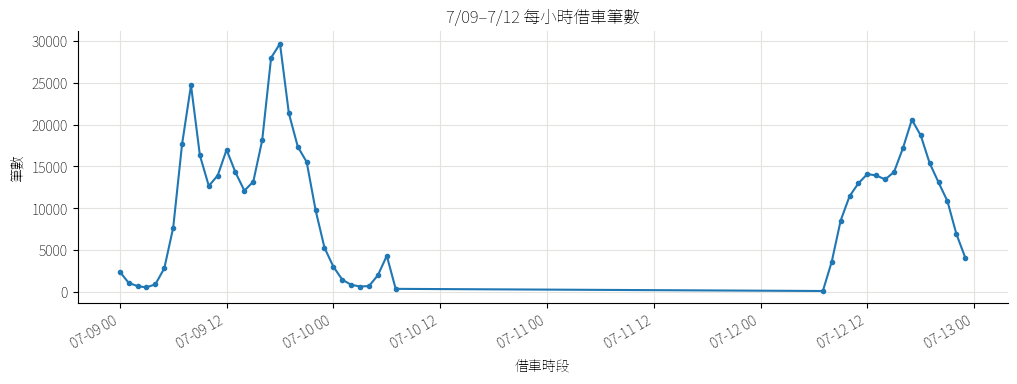

,借車時段,筆數
2,2026-07-09 02:00:00,675
3,2026-07-09 03:00:00,529
4,2026-07-09 04:00:00,899
26,2026-07-10 02:00:00,840
27,2026-07-10 03:00:00,632
28,2026-07-10 04:00:00,690
31,2026-07-10 07:00:00,354
32,2026-07-12 07:00:00,97


In [ ]:
hourly = duckdb.sql(f"""
SELECT
    rent_time AS 借車時段,
    COUNT(*)  AS 筆數
FROM read_csv('{CSV_PATH}', types={{'rent': 'VARCHAR'}})
WHERE rent_time >= '2026-07-09' AND rent_time < '2026-07-13'
GROUP BY 1
ORDER BY 1
""").df()

# types={{'rent': 'VARCHAR'}}：只把 rent 指定成文字，其他欄位照常自動判斷
#   f-string 裡的 { } 會被當成變數，所以要寫成 {{ }}，送進 SQL 時才會變回 { }
# < '2026-07-13'：「小於 7/13 零點」，剛好包含 7/12 整天
# GROUP BY 1 / ORDER BY 1：1 代表 SELECT 的第 1 個欄位
# .df()：把查詢結果轉成 pandas DataFrame，方便畫圖

ax = hourly.plot(x="借車時段", y="筆數", figsize=(12, 4), legend=False, marker=".")  # marker：標出每個資料點
ax.set_title("7/09–7/12 每小時借車筆數")
ax.set_ylabel("筆數")
plt.show()

# 把筆數特別少的時段印出來
display(hourly[hourly["筆數"] < 1000])

**看到什麼**

| 時間 | 筆數 | 狀況 |
|---|---|---|
| 7/10（五）06:00 | 約 4,200 | 正常，早上的使用量正在上升 |
| 7/10 07:00 | **354** | 平常這時候會衝到 1 萬筆以上，這一小時中途就斷了 |
| 7/10 08:00 → 7/12 06:00 | **沒有任何資料** | 缺口約 **47 小時** |
| 7/12（日）07:00 | **97** | 開始恢復 |
| 7/12 08:00 之後 | 回升 | 曲線形狀跟一般週日差不多 |

- 筆數小於 1,000 的時段，除了缺口前後兩小時，其他都是凌晨 2~4 點，屬於正常的低峰。
- ⚠ 圖上 7/10 07:00 到 7/12 07:00 那條斜直線，是 matplotlib 把前後兩個點直接連起來，**不代表那段時間有資料**。

**我的判斷：**（提示：缺口從幾點到幾點、約幾小時？原因可以怎麼查證？這段缺漏會影響哪些特徵（例如 7/17、7/18 的「上週同時段淨流量」）？W2 打算怎麼處理？為什麼不能補 0？）

### 步驟 2：`infodate` 跟借車日期不一樣的有幾筆？

In [ ]:
duckdb.sql(f"""
SELECT COUNT(*) AS 不一致筆數
FROM read_csv('{CSV_PATH}', types={{'rent': 'VARCHAR'}})
WHERE CAST(rent_time AS DATE) != infodate
""").show()

# CAST(rent_time AS DATE)：把「日期＋時間」轉成只剩「日期」
# != 是「不等於」，也可以寫成 <>
# 注意：只要有一邊是空值，比較結果就不是 true，所以空值不會被算進來，要另外檢查

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────┐
│ 不一致筆數 │
│   int64    │
├────────────┤
│          0 │
└────────────┘



**看到什麼**

不一致筆數是 **0**：每一筆的 `infodate` 都等於借車日期。

**我的判斷：**（提示：`infodate` 和 `rent_time` 是什麼關係？之後兩個欄位都需要留嗎？）

## 第 6 段：每個欄位的空值＋完全相同的資料列

**目的**：找出空白的欄位，以及「所有欄位都一模一樣」的資料列。

### 步驟 1：每個欄位有幾個空值

`COUNT(*)` 會算所有列，`COUNT(欄位)` 會跳過空值（NULL），所以兩個相減就是這個欄位的空值數。

In [ ]:
duckdb.sql(f"""
SELECT
    COUNT(*)                         AS 總筆數,
    COUNT(*) - COUNT(rent_time)      AS rent_time_空值,
    COUNT(*) - COUNT(rent_station)   AS rent_station_空值,
    COUNT(*) - COUNT(return_time)    AS return_time_空值,
    COUNT(*) - COUNT(return_station) AS return_station_空值,
    COUNT(*) - COUNT(rent)           AS rent_空值,
    COUNT(*) - COUNT(bike_type)      AS bike_type_空值,
    COUNT(*) - COUNT(infodate)       AS infodate_空值
FROM read_csv('{CSV_PATH}', all_varchar=true)
""").show()

# all_varchar=true：全部用文字讀，不會因為轉換型態失敗而報錯，算到的就是原始檔案裡真正空白的數量

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌─────────┬────────────────┬───────────────────┬──────────────────┬─────────────────────┬───────────┬────────────────┬───────────────┐
│ 總筆數  │ rent_time_空值 │ rent_station_空值 │ return_time_空值 │ return_station_空值 │ rent_空值 │ bike_type_空值 │ infodate_空值 │
│  int64  │     int64      │       int64       │      int64       │        int64        │   int64   │     int64      │     int64     │
├─────────┼────────────────┼───────────────────┼──────────────────┼─────────────────────┼───────────┼────────────────┼───────────────┤
│ 7596992 │              0 │                 0 │                0 │                   4 │         0 │              0 │             0 │
└─────────┴────────────────┴───────────────────┴──────────────────┴─────────────────────┴───────────┴────────────────┴───────────────┘



**看到什麼**

只有 `return_station` 有 **4 筆**空值，其他 6 個欄位都沒有空值。（這 4 筆的內容在第 7 段步驟 3。）

**我的判斷：**（提示：空值多不多？集中在哪個欄位？還車時間有值、還車站卻空白，可能是什麼情況？）

### 步驟 2：完全相同的資料列有幾組

這份資料**沒有 ID 欄位**，所以只能檢查「所有欄位都一模一樣」的列。

In [ ]:
duckdb.sql(f"""
SELECT
    COUNT(*)   AS 重複組數,
    SUM(n - 1) AS 多出來的列數,
    MAX(n)     AS 同一組最多出現幾次
FROM (
    SELECT *, COUNT(*) AS n
    FROM read_csv('{CSV_PATH}', types={{'rent': 'VARCHAR'}})
    GROUP BY ALL
    HAVING COUNT(*) > 1
)
""").show()

# 括號裡是子查詢：先找出每一組重複的列，外面再彙總
# GROUP BY ALL：用 SELECT 裡所有的欄位分組，所有欄位都一樣的列會分在同一組
# HAVING：跟 WHERE 很像，差別是它在「分組之後」才篩選，這裡留下出現超過 1 次的組
# n - 1：一組出現 n 次，扣掉 1 筆原本的，剩下的就是多出來的

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────┬──────────────┬────────────────────┐
│ 重複組數 │ 多出來的列數 │ 同一組最多出現幾次 │
│  int64   │    int128    │       int64        │
├──────────┼──────────────┼────────────────────┤
│    19772 │        20613 │                  9 │
└──────────┴──────────────┴────────────────────┘



**看到什麼**

所有欄位都相同的有 **19,772 組**，多出 **20,613 列**（約占全部的 0.27%），同一組最多出現 **9 次**。

**我的判斷：**（提示：沒有 ID 欄位時，「所有欄位都一樣」能證明是同一趟被記錄兩次嗎？`rent` 精確到秒，這點有什麼幫助？）

## 第 7 段：看實際的重複例子和空值列

**目的**：判斷之前，先看實際的資料長什麼樣子。

### 步驟 1：出現最多次的重複紀錄

In [18]:
dup = duckdb.sql(f"""
SELECT *, COUNT(*) AS n
FROM read_csv('{CSV_PATH}', types={{'rent': 'VARCHAR'}})
GROUP BY ALL
HAVING COUNT(*) > 1
ORDER BY n DESC
LIMIT 20
""").df()

# ORDER BY n DESC：依出現次數由多到少排序（DESC 是遞減）
# LIMIT 20：只取前 20 列

display(dup)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rent_time,rent_station,return_time,return_station,rent,bike_type,infodate,n
0,2026-07-15 04:00:00,福星公園地下停車場(出入口B),2026-07-15 04:00:00,福星公園,00:01:07,一般車,2026-07-15,9
1,2026-07-04 02:00:00,福星公園地下停車場(出入口B),2026-07-04 02:00:00,福星公園,00:01:07,一般車,2026-07-04,8
2,2026-07-02 03:00:00,福星公園,2026-07-02 03:00:00,福星公園地下停車場(出入口B),00:01:07,一般車,2026-07-02,8
3,2026-07-03 04:00:00,臺灣戲曲中心(文林德行西路口),2026-07-03 04:00:00,臺灣戲曲中心,00:01:05,一般車,2026-07-03,7
4,2026-07-05 01:00:00,福星公園,2026-07-05 01:00:00,福星公園地下停車場(出入口B),00:01:07,一般車,2026-07-05,6
5,2026-07-03 03:00:00,臺灣戲曲中心(文林德行西路口),2026-07-03 03:00:00,臺灣戲曲中心,00:01:07,一般車,2026-07-03,6
6,2026-07-28 18:00:00,捷運西門站(2號出口),2026-07-28 18:00:00,捷運西門站(3號出口),00:00:25,一般車,2026-07-28,6
7,2026-07-14 05:00:00,福星公園,2026-07-14 05:00:00,福星公園地下停車場(出入口B),00:01:05,一般車,2026-07-14,6
8,2026-07-14 06:00:00,福星公園,2026-07-14 06:00:00,福星公園地下停車場(出入口B),00:01:07,一般車,2026-07-14,6
9,2026-07-14 06:00:00,福星公園地下停車場(出入口B),2026-07-14 06:00:00,福星公園,00:01:08,一般車,2026-07-14,6


**看到什麼**

前 20 組有共同的規律：
- **相鄰的兩站互騎**：福星公園 ↔ 福星公園地下停車場(出入口B)、臺灣戲曲中心(文林德行西路口) → 臺灣戲曲中心、新奇岩社會住宅 ↔ 奇岩抽水站、捷運象山站(2號出口) ↔ 象山公園、捷運西門站 2 號 ↔ 3 號出口。
- **騎乘時間極短**：大多是 00:01:05 ~ 00:01:08，西門站那組只有 00:00:23 ~ 00:00:25。
- **時段多在深夜到清晨**：01:00 ~ 06:00 最多，全部都是一般車。
- 出現 9 次的那組：7/15 04:00 從福星公園地下停車場(出入口B) 騎到福星公園，騎乘 00:01:07。

### 步驟 2：重複的組，有多少是「原站借還」或「騎不到 5 分鐘」？

In [19]:
duckdb.sql(f"""
SELECT
    rent_station = return_station AS 原站借還,
    rent < '00:05:00'             AS 騎不到5分鐘,
    COUNT(*)                      AS 組數,
    SUM(n - 1)                    AS 多出來的列數
FROM (
    SELECT *, COUNT(*) AS n
    FROM read_csv('{CSV_PATH}', types={{'rent': 'VARCHAR'}})
    GROUP BY ALL
    HAVING COUNT(*) > 1
)
GROUP BY ALL
ORDER BY 組數 DESC
""").show()

# rent_station = return_station：比較的結果是 true / false，直接當成一個欄位
# rent < '00:05:00'：rent 是文字，但格式固定是「時:分:秒」而且小時是兩位數，
#   一個字一個字比的結果剛好等於時間大小（三位數小時的紀錄本來就不會小於 5 分鐘）

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────┬─────────────┬───────┬──────────────┐
│ 原站借還 │ 騎不到5分鐘 │ 組數  │ 多出來的列數 │
│ boolean  │   boolean   │ int64 │    int128    │
├──────────┼─────────────┼───────┼──────────────┤
│ false    │ true        │ 11102 │        11894 │
│ false    │ false       │  8176 │         8223 │
│ true     │ false       │   460 │          460 │
│ true     │ true        │    34 │           36 │
└──────────┴─────────────┴───────┴──────────────┘



**看到什麼**

| 原站借還 | 騎不到 5 分鐘 | 組數 | 多出來的列數 |
|---|---|---|---|
| 否 | 是 | 11,102 | 11,894 |
| 否 | 否 | 8,176 | 8,223 |
| 是 | 否 | 460 | 460 |
| 是 | 是 | 34 | 36 |

- 重複大多**不是**原站借還（原站借還只有 494 組）。
- 「騎不到 5 分鐘」的占一半多，但也有 8,176 組騎超過 5 分鐘。

**我的判斷：**（提示：重複的紀錄比較像「系統重複記錄」，還是「剛好一樣的不同趟」？（想想：熱門路線同一小時有幾十趟，騎乘秒數剛好相同的機率有多高？）W2 打算刪除、保留，還是分情況處理？為什麼？）

### 步驟 3：那 4 筆還車站空白的紀錄

In [20]:
duckdb.sql(f"""
SELECT *
FROM read_csv('{CSV_PATH}', types={{'rent': 'VARCHAR'}})
WHERE return_station IS NULL
""").show()

# IS NULL：判斷空值要用 IS NULL，不能用 = NULL（= NULL 的結果永遠不是 true）

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌─────────────────────┬───────────────────────────┬─────────────────────┬────────────────┬──────────┬───────────┬────────────┐
│      rent_time      │       rent_station        │     return_time     │ return_station │   rent   │ bike_type │  infodate  │
│      timestamp      │          varchar          │      timestamp      │    varchar     │ varchar  │  varchar  │    date    │
├─────────────────────┼───────────────────────────┼─────────────────────┼────────────────┼──────────┼───────────┼────────────┤
│ 2026-07-05 17:00:00 │ 捷運中正紀念堂站(2號出口) │ 2026-07-05 17:00:00 │ NULL           │ 00:03:28 │ 一般車    │ 2026-07-05 │
│ 2026-07-20 17:00:00 │ 永吉公園                  │ 2026-07-20 17:00:00 │ NULL           │ 00:01:43 │ 一般車    │ 2026-07-20 │
│ 2026-07-01 18:00:00 │ 福林公園(福林路)          │ 2026-07-01 19:00:00 │ NULL           │ 00:49:39 │ 一般車    │ 2026-07-01 │
│ 2026-07-19 18:00:00 │ 捷運六張犁站              │ 2026-07-19 18:00:00 │ NULL           │ 00:07:27 │ 一般車    │ 2026-07-19 │
└─────────────────────┴─

**看到什麼**

4 筆都是一般車，借車站、借還時間、騎乘時間都正常（約 1~50 分鐘），只有還車站是空白：
- 7/05 17:00 捷運中正紀念堂站(2號出口)，騎 00:03:28
- 7/20 17:00 永吉公園，騎 00:01:43
- 7/01 18:00 福林公園(福林路)，騎 00:49:39
- 7/19 18:00 捷運六張犁站，騎 00:07:27

**我的判斷：**（提示：這 4 筆算「借出量」時可以用嗎？算「還入量」呢？W2 打算怎麼處理？）

## 第 8 段：驗證調度的推測＋騎乘時間的範圍

**目的**：一、看「相鄰兩站互騎」集中在幾點，判斷比較像一般民眾還是夜間調度。二、把騎乘時間換成分鐘，看數值的範圍（範本第 7 節）。

### 步驟 1：福星公園這兩站的互騎，集中在幾點？

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

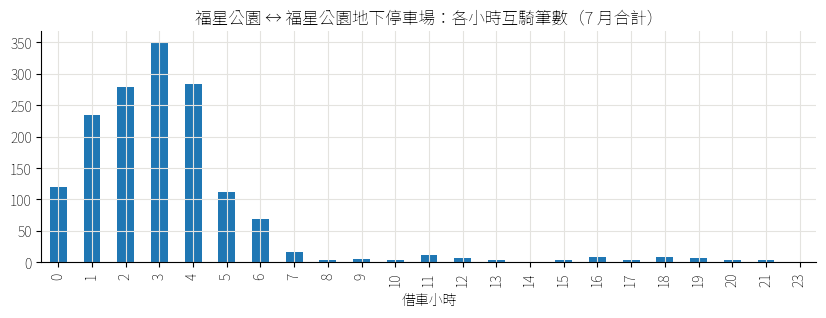

In [21]:
fx = duckdb.sql(f"""
SELECT
    hour(rent_time) AS 借車小時,
    COUNT(*)        AS 筆數
FROM read_csv('{CSV_PATH}', types={{'rent': 'VARCHAR'}})
WHERE rent_station   LIKE '福星公園%'
  AND return_station LIKE '福星公園%'
  AND rent_station <> return_station
GROUP BY 1
ORDER BY 1
""").df()

# hour(rent_time)：取出「小時」（0~23）
# LIKE '福星公園%'：開頭是「福星公園」的站名都算，% 代表後面接什麼都可以
# rent_station <> return_station：排除原站借還，只留兩站互騎

ax = fx.plot.bar(x="借車小時", y="筆數", figsize=(10, 3), legend=False)
ax.set_title("福星公園 ↔ 福星公園地下停車場：各小時互騎筆數（7 月合計）")
plt.show()

**看到什麼**

互騎幾乎全部集中在 **0~6 點**，3 點最多（約 350 筆），7 點以後幾乎是 0；白天和傍晚的通勤尖峰都沒有明顯增加。

**我的判斷：**（提示：這個時段分布比較像一般民眾，還是夜間人員調度？如果是調度，算「需求量」時會造成什麼問題？）

### 步驟 2：騎乘時間換成「分鐘」，看分布

In [22]:
duckdb.sql(f"""
WITH t AS (
    SELECT
        CAST(split_part(rent, ':', 1) AS INTEGER) * 60
      + CAST(split_part(rent, ':', 2) AS INTEGER)
      + CAST(split_part(rent, ':', 3) AS INTEGER) / 60.0 AS 騎乘分鐘
    FROM read_csv('{CSV_PATH}', types={{'rent': 'VARCHAR'}})
)
SELECT
    MIN(騎乘分鐘)                                                AS 最小,
    quantile_cont(騎乘分鐘, [0.01, 0.25, 0.5, 0.75, 0.95, 0.99]) AS 分位數_1_25_50_75_95_99,
    MAX(騎乘分鐘)                                                AS 最大,
    SUM(CASE WHEN 騎乘分鐘 = 0   THEN 1 ELSE 0 END)              AS 剛好0秒,
    SUM(CASE WHEN 騎乘分鐘 < 1   THEN 1 ELSE 0 END)              AS 不到1分鐘,
    SUM(CASE WHEN 騎乘分鐘 > 240 THEN 1 ELSE 0 END)              AS 超過4小時
FROM t
""").show()

# 時 × 60 + 分 + 秒 ÷ 60 = 總分鐘數；除以 60.0（不是 60）才會保留小數
# quantile_cont：一次算出好幾個分位數，例如 0.5 就是中位數
# SUM(CASE WHEN 條件 THEN 1 ELSE 0 END)：符合條件記 1、不符合記 0，加總就是符合的筆數

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────┬─────────────────────────────────────────────────────────────────────────────┬────────────────────┬─────────┬───────────┬───────────┐
│  最小  │                           分位數_1_25_50_75_95_99                           │        最大        │ 剛好0秒 │ 不到1分鐘 │ 超過4小時 │
│ double │                                  double[]                                   │       double       │ int128  │  int128   │  int128   │
├────────┼─────────────────────────────────────────────────────────────────────────────┼────────────────────┼─────────┼───────────┼───────────┤
│    0.0 │ [1.6, 4.75, 8.066666666666666, 15.05, 39.21666666666667, 91.73333333333333] │ 23180.033333333333 │       7 │     13067 │      6104 │
└────────┴─────────────────────────────────────────────────────────────────────────────┴────────────────────┴─────────┴───────────┴───────────┘



**看到什麼**

| 指標 | 騎乘分鐘 |
|---|---|
| 最小 | 0 |
| 1% | 1.6 |
| 25% | 4.75 |
| 中位數 | 8.1 |
| 75% | 15.1 |
| 95% | 39.2 |
| 99% | 91.7 |
| 最大 | 23,180（約 16 天） |

- 剛好 0 秒：**7 筆**；不到 1 分鐘：**13,067 筆**；超過 4 小時：**6,104 筆**（約 0.08%）。
- 一半的騎乘不到 8 分鐘，大多是短程接駁，跟資料定義文件一致。

**我的判斷：**（提示：大部分的騎乘多長？哪些值不合理（0 秒、超過 4 小時）？哪些可能合理（不到 1 分鐘）？W2 想怎麼設定上下限？）

## 尚未完成的範本項目

- **第 1 節　了解專案**：1.1 基本資訊（題目、資料來源、網址、取得日期、任務類型、預測目標）、1.2 變數說明
- **第 8 節　類別欄位與代碼對照**：`bike_type` 有哪些值？站名有沒有亂碼或寫法不同的情況？
- **第 9 節　目標檢查**：彙總成「站 × 小時」後，淨流量（還入量 − 借出量）的分布
- **第 10 節　本週小結**：三個最重要的發現、W2 要處理的問題清單、想問講師的問題